# nb136 drafts · FQ3 + FQ2
Follow-ups to nb136 Q3 (where position lives in the input) and Q2 / Q1 (how the bands are used), on run **decres-rescale-aug10-v1** (`src9/arch/transformer4.py`, eager fp32, IoU @ 0.08).
Same fixed sets as Q1 (`subset720.npz`): 60 each of candle / red-cube / soap dispenser / vase per box, **240 per box**, train and ID eval.
Caches: `scripts/nb136_fq3.py SET` → `fq3_{SET}.npz`, `scripts/nb136_fq2.py SET` → `fq2_{SET}.npz`. Relative drop = Σ(clean − edited) / Σ clean per box (same `rel` as nb136 Q1), shown as **% of clean IoU**.

In [1]:
import numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from scipy.signal import savgol_filter, find_peaks
from scipy.ndimage import maximum_filter1d
ROOT = Path.cwd().parents[1] if Path.cwd().name == "drafts_136" else Path.cwd()
CACHE = ROOT / "runs/_src9_cache/nb136"
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
BX, SETS = ["plastic", "gastro", "cardboard"], ["train", "eval"]
BOXC, CMAP = {"plastic": "tab:blue", "gastro": "tab:green", "cardboard": "tab:orange"}, {"plastic": "Blues", "gastro": "Greens", "cardboard": "Oranges"}
HZ, FHZ = 100 + (np.arange(18) * 65 + 32) * 900 / 1169, np.linspace(100, 1000, 1170)       # band centres (50 Hz bands), bin Hz
Q = {s: np.load(CACHE / f"q1_{s}.npz") for s in SETS}; F3 = {s: np.load(CACHE / f"fq3_{s}.npz") for s in SETS}; F2 = {s: np.load(CACHE / f"fq2_{s}.npz") for s in SETS}
for s in SETS: assert (F3[s]["rows"] == Q[s]["rows"]).all() and (F2[s]["rows"] == Q[s]["rows"]).all()
c0 = {s: {b: Q[s]["clean"][Q[s]["box"] == b].mean() for b in BX} for s in SETS}
absd = lambda r, cl: r * np.clip(cl, 1e-3, None)                                   # caches store per-sample (clean − e) / max(clean, 1e-3) -> back to clean − e
print({s: {b: round(float(c0[s][b]), 3) for b in BX} for s in SETS})

{'train': {'plastic': 0.926, 'gastro': 0.911, 'cardboard': 0.909}, 'eval': {'plastic': 0.692, 'gastro': 0.711, 'cardboard': 0.619}}


## FQ3 · What spectral change carries position?
For each of the 18 bands (65 bins, 50 Hz), one counterfactual edit of **that band only**, applied to |X| before the model's per-sample z-score (`transformer4.py:139`), so the normalisation still runs:
- **pattern** (across-laser pattern removed): every laser gets the band's laser-mean spectrum, per axis;
- **amp** (amplitude removed): each laser's band rescaled to the band's mean level over lasers, shape kept;
- **shift ±1, ±2**: the band rolled by k bins (0.77 Hz / bin), edge-padded;
- **smooth**: 9-bin boxcar (≈ 7 Hz) within the band, edge-padded;
- **key-mask**: the band token dropped through the model's key mask (nb136 Q1 cache `q1_{SET}.npz`).

Note pattern ⊃ amp: removing the across-laser pattern also removes the across-laser level differences. Shift and smooth keep the spatial pattern but move / blur the spectral lines.

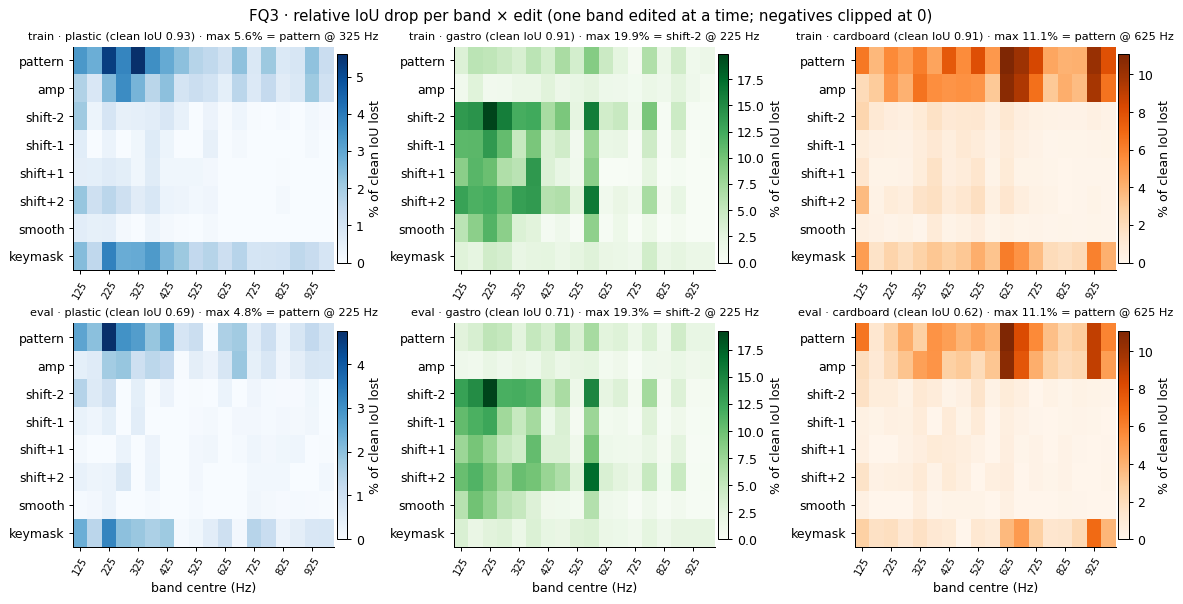

In [2]:
ED = ["pattern", "amp", "shift-2", "shift-1", "shift+1", "shift+2", "smooth", "keymask"]
def drops(s):   # {box: (8 edits, 18 bands)} relative IoU drop, % of clean
    r, box, cl = F3[s]["drop"], F3[s]["box"], F3[s]["clean"]; out = {}
    for b in BX:
        m = box == b; d = np.stack([absd(r[i][:, m], cl[m]).mean(1) for i in range(7)] + [Q[s]["mask_b"][m].mean(0)])
        out[b] = 100 * d / c0[s][b]
    return out
DR = {s: drops(s) for s in SETS}
fig, ax = plt.subplots(2, 3, figsize=(13, 6.6), constrained_layout=True)
for i, s in enumerate(SETS):
    for j, b in enumerate(BX):
        v = np.clip(DR[s][b], 0, None); h = ax[i, j].imshow(v, cmap=CMAP[b], vmin=0, aspect="auto")
        plt.colorbar(h, ax=ax[i, j], fraction=.04, pad=.01, label="% of clean IoU lost")
        ax[i, j].set_yticks(range(8), ED); ax[i, j].set_xticks(range(0, 18, 2), [f"{h:.0f}" for h in HZ[::2]], rotation=60, fontsize=8)
        k = np.unravel_index(DR[s][b].argmax(), DR[s][b].shape); ax[i, j].set_title(f"{s} · {b} (clean IoU {c0[s][b]:.2f}) · max {DR[s][b].max():.1f}% = {ED[k[0]]} @ {HZ[k[1]]:.0f} Hz", fontsize=9)
        ax[i, j].set_xlabel("band centre (Hz)" if i else "")
fig.suptitle("FQ3 · relative IoU drop per band × edit (one band edited at a time; negatives clipped at 0)")
plt.show()

In [3]:
import pandas as pd
rows = []
for s in SETS:
    for b in BX:
        d = DR[s][b]; sh1, sh2 = d[[3, 4]].mean(0), d[[2, 5]].mean(0)
        r = {"set": s, "box": b}
        for nm, v in [("pattern", d[0]), ("amp", d[1]), ("shift±1", sh1), ("shift±2", sh2), ("smooth", d[6]), ("keymask", d[7])]:
            r[f"{nm} Σ"] = v.sum().round(1); r[f"{nm} max"] = f"{v.max():.1f}@{HZ[v.argmax()]:.0f}"
        rows.append(r)
T3 = pd.DataFrame(rows).set_index(["set", "box"]); T3

pattern Σ pattern max      amp Σ   amp max  shift±1 Σ  \
set   box                                                                 
train plastic     44.299999     5.6@325  27.500000   3.6@275   2.800000   
      gastro      74.500000     9.0@575  28.299999   2.9@175  80.699997   
      cardboard  117.500000    11.1@625  98.800003  10.7@625   8.800000   
eval  plastic     29.000000     4.8@225  14.700000   1.9@275   1.300000   
      gastro      62.400002     6.8@575  25.000000   2.7@425  70.599998   
      cardboard   88.000000    11.1@625  72.500000  10.7@625   5.100000   

                shift±1 max   shift±2 Σ shift±2 max   smooth Σ smooth max  \
set   box                                                                   
train plastic       0.7@375    7.500000     2.1@125   1.600000    0.6@125   
      gastro       12.1@225  133.699997    16.2@575  53.599998   11.6@225   
      cardboard     1.4@375   15.300000     3.0@125   4.600000    0.9@375   
eval  plastic       0.2@225    2.600000     0.9@125   0.500000    0.3@225   
      gastro       10.5@175  117.599998    15.9@575  50.700001    9.7@175   
      cardboard     0.9@425    8.700000     1.6@125   2.100000    0.6@325   

                 keymask Σ keymask max  
set   box                               
train plastic    34.200001     3.8@225  
      gastro     43.000000     4.3@225  
      cardboard  60.700001     6.1@625  
eval  plastic    20.600000     3.2@225  
      gastro     39.500000     3.4@125  
      cardboard  40.200001     6.9@925

In [4]:
# where in frequency does each edit act: importance-weighted mean band Hz, and rank agreement with key-masking (Spearman over the 18 bands)
rows = []
for s in SETS:
    for b in BX:
        d = np.clip(DR[s][b], 0, None); r = {"set": s, "box": b}
        for i, nm in enumerate(ED[:-1]): r[f"{nm} ρ(mask)"] = round(stats.spearmanr(DR[s][b][i], DR[s][b][7])[0], 2)
        for i, nm in [(0, "pattern"), (1, "amp"), (2, "shift-2"), (6, "smooth"), (7, "keymask")]: r[f"{nm} Hz̄"] = int((d[i] * HZ).sum() / d[i].sum())
        rows.append(r)
pd.DataFrame(rows).set_index(["set", "box"])

pattern ρ(mask)  amp ρ(mask)  shift-2 ρ(mask)  \
set   box                                                        
train plastic               0.85         0.68             0.81   
      gastro                0.58         0.30             0.73   
      cardboard             0.88         0.59             0.32   
eval  plastic               0.73         0.47             0.58   
      gastro                0.55         0.50             0.51   
      cardboard             0.48         0.36            -0.04   

                 shift-1 ρ(mask)  shift+1 ρ(mask)  shift+2 ρ(mask)  \
set   box                                                            
train plastic               0.58             0.74             0.71   
      gastro                0.71             0.64             0.65   
      cardboard             0.32             0.38             0.38   
eval  plastic               0.27            -0.02             0.56   
      gastro                0.53             0.54             0.47   
      cardboard             0.03            -0.40            -0.38   

                 smooth ρ(mask)  pattern Hz̄  amp Hz̄  shift-2 Hz̄  \
set   box                                                            
train plastic              0.58          442      486          319   
      gastro               0.71          493      532          393   
      cardboard            0.14          577      593          425   
eval  plastic              0.27          421      498          304   
      gastro               0.50          499      527          375   
      cardboard           -0.21          588      612          422   

                 smooth Hz̄  keymask Hz̄  
set   box                                 
train plastic           241          463  
      gastro            323          508  
      cardboard         436          576  
eval  plastic           477          422  
      gastro            332          515  
      cardboard         435          639

### FQ3 · gradient × input at full 1170-bin resolution
∂(soft Dice)/∂|X| · |X| per sample (soft Dice = 2Σpy / (Σp + Σy), p = sigmoid of the mask logits, the IoU proxy), **|g·x| summed over the 100 lasers and 2 axes**, averaged over the box's 240 samples (absolute, so position-dependent signs of opposite laser groups do not cancel). Ticks = the box's **relaxed resonances** from nb136 Q1b (same rule: savgol σ(f), prominence ≥ 2 × MAD from a 60 Hz baseline, present in ≥ 50% of captures of an (object, speaker) group), computed on the same set.

{('train', 'plastic'): 5, ('train', 'gastro'): 22, ('train', 'cardboard'): 7, ('eval', 'plastic'): 5, ('eval', 'gastro'): 22, ('eval', 'cardboard'): 6}


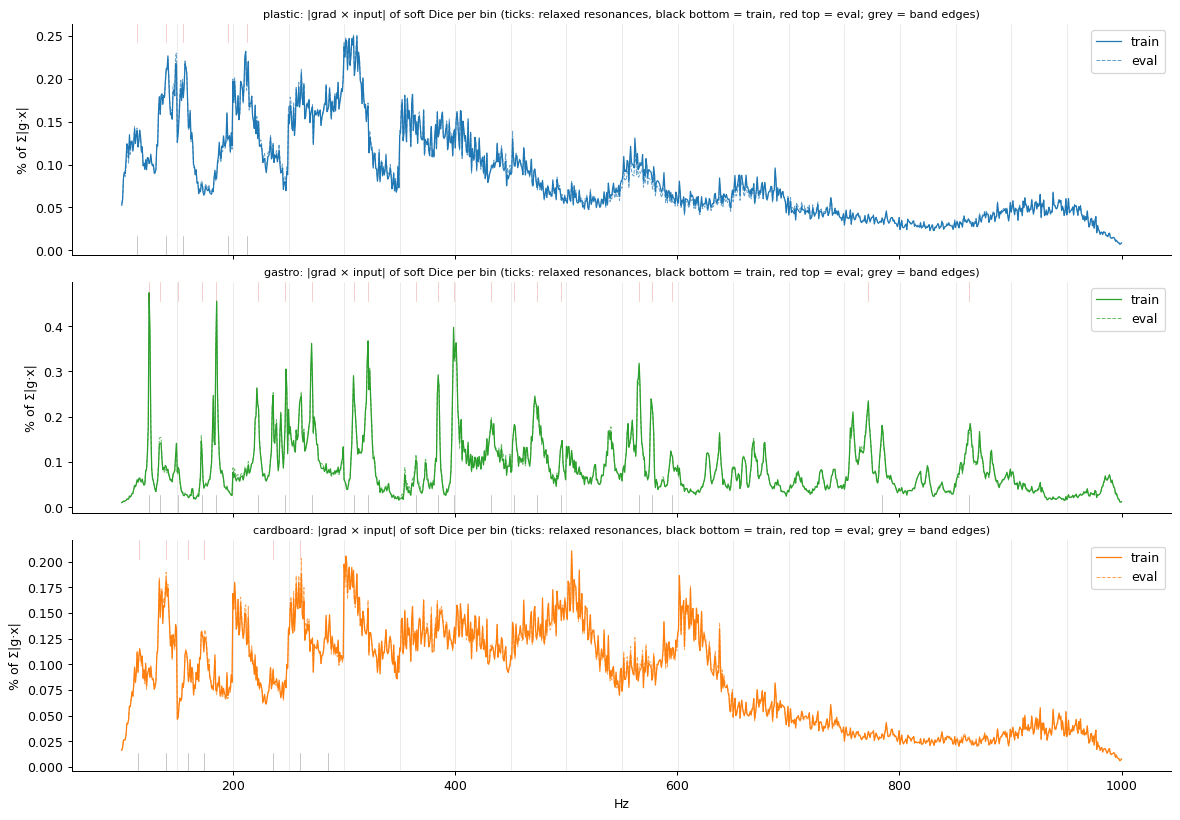

In [5]:
def peaks(sig, k_prom=2., baseline_hz=60., distance_hz=5., smooth_hz=5.):    # nb136 Q1b / nb109 §12 rule, relaxed defaults
    nb = lambda hz: max(1, int(round(hz * 1.3))); odd = lambda n: n + 1 - n % 2
    sig = savgol_filter(sig, odd(2 * nb(smooth_hz) + 1), 3); r = sig - savgol_filter(sig, odd(2 * nb(baseline_hz) + 1), 3)
    return find_peaks(sig, distance=nb(distance_hz), prominence=max(1e-12, k_prom * 1.4826 * np.median(np.abs(r - np.median(r)))), wlen=odd(2 * nb(baseline_hz) + 1))[0]
RES = {}
for s in SETS:
    q = Q[s]
    for b in BX:
        O, Sg = [], []
        for o in np.unique(q["obj"]):
            for sp in np.unique(q["spk"]):
                g = (q["box"] == b) & (q["obj"] == o) & (q["spk"] == sp)
                if g.sum() < 3: continue
                hit = np.zeros(q["sigma"][g].shape, np.uint8)
                for i, x in enumerate(q["sigma"][g]): hit[i, peaks(x)] = 1
                O.append(maximum_filter1d(hit, 7, axis=1).mean(0)); Sg.append(q["sigma"][g].mean(0))
        occ = np.mean(O, 0); RES[s, b] = np.array([k for k in peaks(np.mean(Sg, 0)) if occ[k] >= .5])
print({k: len(v) for k, v in RES.items()})
GX = {(s, b): F3[s]["agx"][F3[s]["box"] == b].sum(-1).mean(0) for s in SETS for b in BX}    # (1170,) mean |g·x|
fig, ax = plt.subplots(3, 1, figsize=(13, 9), sharex=True, constrained_layout=True)
for j, b in enumerate(BX):
    for s, ls in zip(SETS, ["-", "--"]): g = GX[s, b]; ax[j].plot(FHZ, g / g.sum() * 100, ls, color=BOXC[b], lw=1 if s == "train" else .8, alpha=1 if s == "train" else .7, label=s)
    for k in RES["train", b]: ax[j].axvline(FHZ[k], color="k", lw=.5, alpha=.35, ymax=.08)
    for k in RES["eval", b]: ax[j].axvline(FHZ[k], color="tab:red", lw=.5, alpha=.35, ymin=.92)
    for e in 100 + np.arange(1, 18) * 65 * 900 / 1169: ax[j].axvline(e, color="0.85", lw=.4, zorder=0)
    ax[j].set_ylabel("% of Σ|g·x|"); ax[j].set_title(f"{b}: |grad × input| of soft Dice per bin (ticks: relaxed resonances, black bottom = train, red top = eval; grey = band edges)", fontsize=9); ax[j].legend(loc="upper right")
ax[-1].set_xlabel("Hz"); plt.show()

In [6]:
# top lines: the 10 largest local maxima of mean |g·x| (≥ 5 Hz apart); distance to nearest relaxed resonance; chance = share of bins within ±3 Hz of any resonance
rows = []
for s in SETS:
    for b in BX:
        g, res = GX[s, b], RES[s, b]; pk = find_peaks(g, distance=7)[0]; top = pk[np.argsort(-g[pk])[:10]]
        dist = np.array([np.abs(FHZ[res] - FHZ[k]).min() for k in top]); near = np.abs(FHZ[:, None] - FHZ[res][None]).min(1) <= 3
        share = g[near].sum() / g.sum()
        rows.append({"set": s, "box": b, "top lines (Hz)": " ".join(f"{FHZ[k]:.0f}" for k in top), "Δ to nearest res (Hz)": " ".join(f"{d:.0f}" for d in dist),
                     "top10 within ±3 Hz": f"{(dist <= 3).sum()}/10", "chance": f"{near.mean():.2f}", "|g·x| mass within ±3 Hz": f"{share:.2f}",
                     "top-10 share of mass": f"{g[top].sum() / g.sum():.3f}"})
TG = pd.DataFrame(rows).set_index(["set", "box"]); pd.set_option("display.max_colwidth", 80); TG

top lines (Hz)  \
set   box                                                  
train plastic    309 302 212 142 149 157 262 317 200 295   
      gastro     125 185 399 322 271 566 248 385 309 222   
      cardboard  505 302 307 512 262 602 140 134 202 612   
eval  plastic    312 302 149 212 142 157 262 202 317 295   
      gastro     125 185 399 322 271 566 248 309 385 222   
      cardboard  505 262 302 140 307 512 134 602 202 612   

                          Δ to nearest res (Hz) top10 within ±3 Hz chance  \
set   box                                                                   
train plastic         95 89 2 2 7 2 49 104 5 82               3/10   0.03   
      gastro                0 1 0 0 1 0 1 0 1 1              10/10   0.13   
      cardboard  219 16 22 226 2 316 0 6 28 326               2/10   0.04   
eval  plastic         99 89 6 2 2 2 49 6 104 82               3/10   0.03   
      gastro                0 1 0 0 1 0 1 1 0 1              10/10   0.13   
      cardboard  245 2 42 0 47 252 6 342 28 352               2/10   0.04   

                |g·x| mass within ±3 Hz top-10 share of mass  
set   box                                                     
train plastic                      0.06                0.022  
      gastro                       0.27                0.035  
      cardboard                    0.06                0.019  
eval  plastic                      0.06                0.022  
      gastro                       0.27                0.035  
      cardboard                    0.05                0.019

In [7]:
# |g·x| per band vs the per-band edits (Spearman over 18 bands), and the resonance list itself
for s in SETS:
    print(s, {b: {nm: round(stats.spearmanr(GX[s, b].reshape(18, 65).sum(1), DR[s][b][i])[0], 2) for i, nm in [(0, "pattern"), (2, "shift-2"), (6, "smooth"), (7, "keymask")]} for b in BX})
for b in BX: print(b, "train resonances (Hz):", " ".join(f"{FHZ[k]:.0f}" for k in RES["train", b]))

train {'plastic': {'pattern': np.float64(0.89), 'shift-2': np.float64(0.79), 'smooth': np.float64(0.65), 'keymask': np.float64(0.89)}, 'gastro': {'pattern': np.float64(0.68), 'shift-2': np.float64(0.7), 'smooth': np.float64(0.62), 'keymask': np.float64(0.7)}, 'cardboard': {'pattern': np.float64(0.08), 'shift-2': np.float64(0.76), 'smooth': np.float64(0.61), 'keymask': np.float64(0.04)}}
eval {'plastic': {'pattern': np.float64(0.79), 'shift-2': np.float64(0.17), 'smooth': np.float64(-0.22), 'keymask': np.float64(0.61)}, 'gastro': {'pattern': np.float64(0.79), 'shift-2': np.float64(0.64), 'smooth': np.float64(0.56), 'keymask': np.float64(0.36)}, 'cardboard': {'pattern': np.float64(-0.02), 'shift-2': np.float64(0.59), 'smooth': np.float64(0.36), 'keymask': np.float64(-0.57)}}
plastic train resonances (Hz): 114 140 155 195 213
gastro train resonances (Hz): 125 135 151 172 185 222 247 272 309 322 365 385 399 433 453 473 496 566 577 595 784 863
cardboard train resonances (Hz): 115 140 159 17

**FQ3 answer** (240 samples per box; numbers train / eval, % of clean IoU lost by editing one band; Σ = summed over the 18 single-band edits).

**The answer differs by box: gastro reads exact line frequencies, plastic and cardboard read the across-laser pattern.**
- **Gastro: a frequency shift dominates.** Moving one band by **±1 bin (0.77 Hz)** costs up to **12.1 / 10.5%** (225 / 175 Hz). ±2 bins costs up to **16.2 / 15.9%** (575 Hz) and Σ **134 / 118%**. A 7 Hz smooth costs Σ 54 / 51%. All three exceed **dropping the band** (key-mask Σ 43 / 40%, max 4.3 / 3.4%) and the across-laser pattern edit (Σ 75 / 62%, max 9.0 / 6.8% @ 575 Hz). Amplitude matters little (Σ 28 / 25%). A slightly mistuned band is worse than a missing one: the model treats it as a confident, wrong cue. The sensitivity sits in the 125–375 Hz bands and at 575 Hz.
- **Cardboard: the across-laser pattern dominates, carried mostly by its amplitude.** pattern Σ **118 / 88%**, max **11.1%** @ 625 Hz in both sets. amp Σ 99 / 73%, max 10.7% @ 625 Hz. The 625–675 and 925–975 Hz bands carry it, the same high bands key-masking flags. Shift is ≤ 3.0% per band (Σ 15 / 9%) and smoothing ≤ 0.9%.
- **Plastic: the across-laser pattern dominates, weakly.** pattern max 5.6 / 4.8% (325 / 225 Hz), Σ 44 / 29%. amp Σ 28 / 15%. Shift and smooth barely matter (≤ 2.1%, Σ ≤ 7.5%).
- **Pattern vs amplitude.** Removing only the level differences between lasers (amp) gives 50–85% of the full pattern effect in plastic and cardboard but only ~40% in gastro. In gastro the spatial information is in the spectral shape per laser, not in the level.
- **Rank agreement with key-masking** (ρ over bands): pattern .85 / .73 (plastic), .88 / .48 (cardboard). In gastro shift and smooth agree with key-masking as well as pattern does (ρ ≈ .5–.7).

**grad × input (1170 bins)**
- **Gastro:** sharp spikes. **All 10 top lines lie within 1 Hz of a relaxed resonance**: 125, 185, 399, 322, 271, 566, 248, 385, 309, 222 Hz (chance .13 per line). 27% of all |g·x| mass falls within ±3 Hz of the 22 resonances, which cover 13% of the bins. This is the mechanism behind the shift sensitivity: the model locks onto the gastro modes, consistent with mass-loading mode shifts (Q2).
- **Plastic and cardboard:** broad humps, not lines. Plastic 300–320, 140–160, 200–215 Hz; cardboard 500–512, 600–612, 260, 300 Hz. Only 2–3 of 10 top lines fall near one of their 5–7 relaxed resonances (chance .03–.04). The |g·x| mass near resonances is 5–6%, about 1.5× chance. In plastic the low resonances (140, 155, 213 Hz) do coincide with gradient humps. The large cardboard lines (505, 602 Hz) are not resonances by the relaxed rule.
- Train and eval spectra are almost identical, so the gradient map is a property of the model, not of the sample set.
- Per-band Σ|g·x| tracks the pattern/key-mask importance in plastic (ρ .89 / .79 with pattern) but not in cardboard (ρ ≈ 0): there the high bands matter through the edits while the gradient sits at 300–600 Hz.

## FQ2 · Redundancy vs synergy between bands
- **Pairwise key-masking** of all 153 band pairs (plus the 18 singles, recomputed in the same pass), per sample. Interaction **I(i,j) = Δij − Δi − Δj** on the box-level relative drop (% of clean IoU): **negative = redundant** (dropping both costs less than the sum; one covers for the other), **positive = synergy** (the pair carries information neither carries alone).
- **Shapley values** per band: v(S) = mean IoU of the box's 240 samples with only bands S kept (the rest key-masked); 200 random permutations per box (100 antithetic pairs, one permutation shared by all samples of the box), φᵢ = mean marginal gain when band i is added. v(∅) = no band kept (the freq readout reduces to its bias). By efficiency Σφ = v(all) − v(∅). The forward runs on the kept band tokens only (exactly equal to key-masking, checked in the script).
- Shapley ranking vs single-band masking ranking (Spearman over 18 bands), and the top-K keep curve / **K90** (bands kept for 90% of clean IoU) with the Shapley order, vs masking order from nb136 Q1 (`c|box|band|masking`).

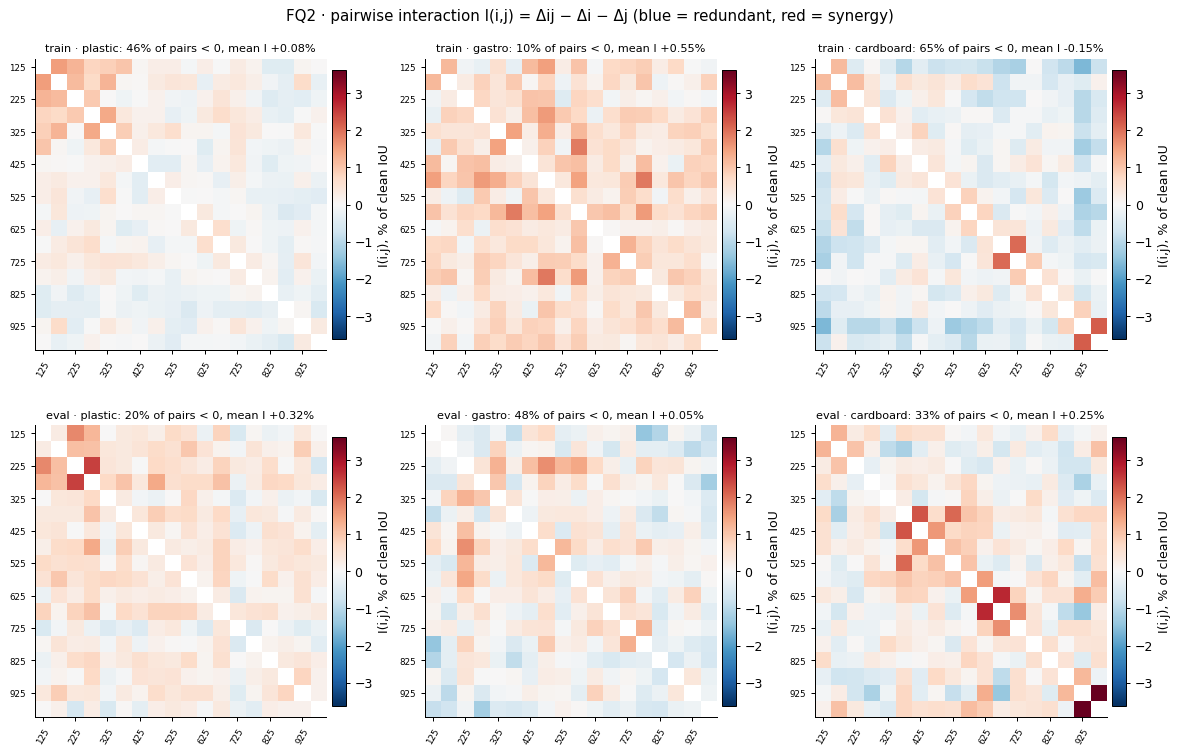

In [8]:
def inter(s):  # {box: (18,18)} I(i,j) in % of clean IoU, plus singles and pair drops
    f, out = F2[s], {}
    for b in BX:
        m = f["box"] == b; cl = f["clean"][m]; d1 = absd(f["single"][m], cl[:, None]).mean(0) / c0[s][b] * 100
        d2 = absd(np.nan_to_num(f["pair"][m]), cl[:, None, None]).mean(0) / c0[s][b] * 100
        I = d2 - d1[:, None] - d1[None]; np.fill_diagonal(I, np.nan); out[b] = (I, d1, d2)
    return out
IN = {s: inter(s) for s in SETS}
lim = max(np.nanmax(np.abs(IN[s][b][0])) for s in SETS for b in BX)
fig, ax = plt.subplots(2, 3, figsize=(13, 8.4), constrained_layout=True)
for i, s in enumerate(SETS):
    for j, b in enumerate(BX):
        I = IN[s][b][0]; h = ax[i, j].imshow(I, cmap="RdBu_r", vmin=-lim, vmax=lim)
        iu = np.triu_indices(18, 1); v = I[iu]
        ax[i, j].set_title(f"{s} · {b}: {(v < 0).mean() * 100:.0f}% of pairs < 0, mean I {v.mean():+.2f}%", fontsize=9)
        ax[i, j].set_xticks(range(0, 18, 2), [f"{h:.0f}" for h in HZ[::2]], rotation=60, fontsize=7); ax[i, j].set_yticks(range(0, 18, 2), [f"{h:.0f}" for h in HZ[::2]], fontsize=7)
        plt.colorbar(h, ax=ax[i, j], fraction=.046, pad=.02, label="I(i,j), % of clean IoU")
fig.suptitle("FQ2 · pairwise interaction I(i,j) = Δij − Δi − Δj (blue = redundant, red = synergy)"); plt.show()

In [9]:
rows = []
for s in SETS:
    for b in BX:
        I, d1, d2 = IN[s][b]; v = I[np.triu_indices(18, 1)]; k = np.unravel_index(np.nanargmin(I), I.shape); kk = np.unravel_index(np.nanargmax(I), I.shape)
        nb = np.array([I[i, i + 1] for i in range(17)])
        rows.append({"set": s, "box": b, "Σ singles %": d1.sum().round(1), "mean pair Δij %": d2[np.triu_indices(18, 1)].mean().round(2),
                     "mean I %": v.mean().round(2), "median I %": np.median(v).round(2), "share I<0": (v < 0).mean().round(2), "share |I|>1%": (np.abs(v) > 1).mean().round(2),
                     "most redundant": f"{HZ[k[0]]:.0f}+{HZ[k[1]]:.0f}: {I[k]:+.1f}", "most synergistic": f"{HZ[kk[0]]:.0f}+{HZ[kk[1]]:.0f}: {I[kk]:+.1f}",
                     "adjacent-band mean I %": nb.mean().round(2), "I ~ |i−j| ρ": round(stats.spearmanr(v, np.subtract(*np.triu_indices(18, 1)) * -1)[0], 2)})
pd.DataFrame(rows).set_index(["set", "box"])

Σ singles %  mean pair Δij %  mean I %  median I %  \
set   box                                                             
train plastic      34.200001             3.88      0.08        0.02   
      gastro       43.000000             5.33      0.55        0.53   
      cardboard    60.700001             6.60     -0.15       -0.16   
eval  plastic      20.600000             2.61      0.32        0.33   
      gastro       39.500000             4.44      0.05        0.05   
      cardboard    40.200001             4.72      0.25        0.18   

                 share I<0  share |I|>1% most redundant most synergistic  \
set   box                                                                  
train plastic         0.46          0.04  875+975: -0.6    125+175: +1.5   
      gastro          0.10          0.14  225+525: -0.5    475+775: +1.9   
      cardboard       0.65          0.08  125+925: -1.6    975+925: +2.2   
eval  plastic         0.20          0.05  225+975: -0.6    275+225: +2.5   
      gastro          0.48          0.07  125+775: -1.4    475+225: +1.7   
      cardboard       0.33          0.12  675+925: -1.4    925+975: +3.6   

                 adjacent-band mean I %  I ~ |i−j| ρ  
set   box                                             
train plastic                      0.46        -0.21  
      gastro                       0.67        -0.16  
      cardboard                    0.81        -0.50  
eval  plastic                      0.48        -0.16  
      gastro                       0.30        -0.24  
      cardboard                    1.20        -0.35

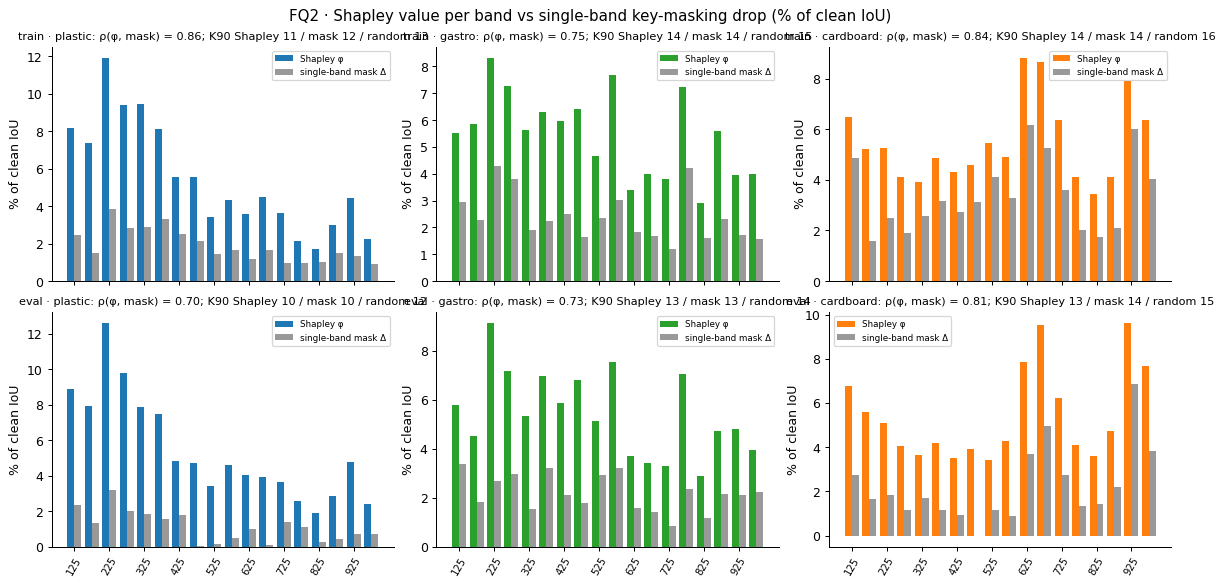

v(all)   v(∅)  Σφ %  Σ mask Δ % φ top-3 (Hz) mask top-3 (Hz)  \
set   box                                                                       
train plastic     0.926  0.013  98.6   34.200001  225 325 275     225 375 325   
      gastro      0.911  0.014  98.4   43.000000  225 575 275     225 775 275   
      cardboard   0.909  0.011  98.8   60.700001  625 675 925     625 925 675   
eval  plastic     0.692  0.013  98.1   20.600000  225 275 125     225 125 275   
      gastro      0.711  0.014  98.0   39.500000  225 575 275     125 575 375   
      cardboard   0.619  0.014  97.8   40.200001  925 675 625     925 675 975   

                 max φ %  min φ %  ρ(φ, mask)  ρ(φ 1st, 2nd 100 perms)  \
set   box                                                                
train plastic       11.9      1.7        0.86                     0.98   
      gastro         8.3      2.9        0.75                     0.86   
      cardboard      8.8      3.4        0.84                     0.94   
eval  plastic       12.6      1.9        0.70                     0.97   
      gastro         9.1      2.9        0.73                     0.89   
      cardboard      9.6      3.4        0.81                     0.88   

                 K90 Shapley  K90 mask  K90 random  K50 Shapley  K50 mask  
set   box                                                                  
train plastic             11        12          13            5         5  
      gastro              14        14          15            6         7  
      cardboard           14        14          16            7         7  
eval  plastic             10        10          12            5         4  
      gastro              13        13          14            6         6  
      cardboard           13        14          15            6         6

In [10]:
# Shapley vs single-band masking; K90 with each ranking
def k90(c, c_clean, fr=.9): r = np.asarray(c) / c_clean; return int(np.argmax(r >= fr)) + 1 if (r >= fr).any() else 18
def phi_of(f, b, T):  # Shapley from a subset T of the stored permutations: marginal gains from the stored v(S) chains
    P, V, v0 = f[f"perm|{b}"][T], f[f"V|{b}"][T], f[f"v0|{b}"]; g = np.diff(np.c_[np.full(len(V), v0), V], axis=1); out = np.zeros(18)
    for o, gg in zip(P, g): out[o] += gg
    return out / len(T)
fig, ax = plt.subplots(2, 3, figsize=(13, 6.4), constrained_layout=True, sharex=True); rows = []
for i, s in enumerate(SETS):
    f = F2[s]
    for j, b in enumerate(BX):
        phi = 100 * f[f"phi|{b}"] / c0[s][b]; msk = DR[s][b][7]; v0 = f[f"v0|{b}"]
        n = len(f[f"V|{b}"]); half = [phi_of(f, b, np.arange(n // 2)), phi_of(f, b, np.arange(n // 2, n))]; assert np.allclose(phi_of(f, b, np.arange(n)), f[f"phi|{b}"])
        w = .4; ax[i, j].bar(np.arange(18) - w / 2, phi, w, color=BOXC[b], label="Shapley φ"); ax[i, j].bar(np.arange(18) + w / 2, msk, w, color="0.6", label="single-band mask Δ")
        rho = stats.spearmanr(phi, msk)[0]; cs = Q[s][f"c|{b}|band|masking"]; cr = np.mean([Q[s][f"c|{b}|band|random{r}"] for r in range(3)], 0)
        ksh, kms, krd = k90(f[f"c|{b}|shapley"], c0[s][b]), k90(cs, c0[s][b]), k90(cr, c0[s][b])
        ax[i, j].set_title(f"{s} · {b}: ρ(φ, mask) = {rho:.2f}; K90 Shapley {ksh} / mask {kms} / random {krd}", fontsize=9)
        ax[i, j].set_xticks(range(0, 18, 2), [f"{h:.0f}" for h in HZ[::2]], rotation=60, fontsize=8); ax[i, j].set_ylabel("% of clean IoU"); ax[i, j].legend(fontsize=7)
        rows.append({"set": s, "box": b, "v(all)": round(float(c0[s][b]), 3), "v(∅)": round(float(v0), 3), "Σφ %": phi.sum().round(1), "Σ mask Δ %": msk.sum().round(1),
                     "φ top-3 (Hz)": " ".join(f"{HZ[k]:.0f}" for k in np.argsort(-phi)[:3]), "mask top-3 (Hz)": " ".join(f"{HZ[k]:.0f}" for k in np.argsort(-msk)[:3]),
                     "max φ %": phi.max().round(1), "min φ %": phi.min().round(1), "ρ(φ, mask)": round(rho, 2), "ρ(φ 1st, 2nd 100 perms)": round(stats.spearmanr(*half)[0], 2),
                     "K90 Shapley": ksh, "K90 mask": kms, "K90 random": krd,
                     "K50 Shapley": k90(f[f"c|{b}|shapley"], c0[s][b], .5), "K50 mask": k90(cs, c0[s][b], .5)})
fig.suptitle("FQ2 · Shapley value per band vs single-band key-masking drop (% of clean IoU)"); plt.show()
TS = pd.DataFrame(rows).set_index(["set", "box"]); TS

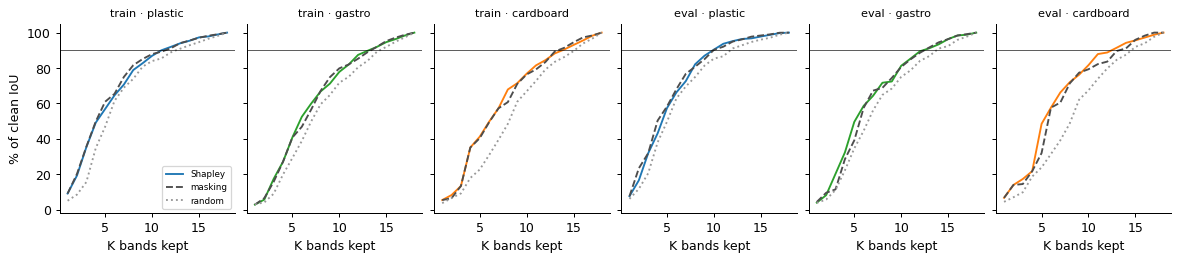

In [11]:
# top-K keep curves: Shapley order vs masking order vs random (nb136 Q1 curves), % of clean IoU
fig, ax = plt.subplots(1, 6, figsize=(13, 2.8), sharey=True, constrained_layout=True)
for i, (s, b) in enumerate([(s, b) for s in SETS for b in BX]):
    K = np.arange(1, 19); f = F2[s]
    ax[i].plot(K, 100 * f[f"c|{b}|shapley"] / c0[s][b], color=BOXC[b], label="Shapley"); ax[i].plot(Q[s]["KB"], 100 * Q[s][f"c|{b}|band|masking"] / c0[s][b], "--", color="0.3", label="masking")
    ax[i].plot(Q[s]["KB"], 100 * np.mean([Q[s][f"c|{b}|band|random{r}"] for r in range(3)], 0) / c0[s][b], ":", color="0.6", label="random")
    ax[i].axhline(90, color="k", lw=.5); ax[i].set_title(f"{s} · {b}", fontsize=9); ax[i].set_xlabel("K bands kept")
ax[0].set_ylabel("% of clean IoU"); ax[0].legend(fontsize=7); plt.show()

**FQ2 answer** (numbers train / eval; I in % of clean IoU).

**The bands are close to additive: neither strongly redundant nor synergistic.**
- **Interactions are small.** Single-band drops are 1–7%, pair drops average 2.6–6.6%, and the mean I is between −0.15 and +0.55%. Only 4–14% of pairs have |I| > 1%; the extremes are −1.6% and +3.6%.
- **The sign is not stable across sets.** Gastro is 90% synergistic on train (mean +.55) but 48 / 52 on eval (+.05). Cardboard is 65% redundant on train (−.15) but 33% on eval (+.25). Plastic is about neutral (46% / 20% negative, +.08 / +.32).
- **One consistent pattern: adjacent bands are mildly synergistic.** Adjacent-band mean I is +.3 to +1.2% in every box and set, and I falls with band distance (ρ(I, |i−j|) −.16 to −.50). Dropping two neighbouring 50 Hz bands removes a whole resonance region that neither alone does. The largest synergies are neighbours: cardboard 925+975 Hz (+2.2 / +3.6%) and 625–725 Hz; plastic 225+275 Hz (+2.5% eval). The few redundant pairs pair a far band with 925 Hz in cardboard, down to −1.6% (125+925 Hz).
- So the many-bands-needed result (K90 13–14 of 18) is **spread-out, mostly additive information**, not a redundant code where one band covers for another.

**Shapley vs masking**
- Over 200 permutations, Σφ = v(all) − v(∅) = 98% of clean (v(∅) = .011–.014). Rankings are stable across the two halves of the permutations (ρ .86–.98).
- Shapley ranking vs single-band key-masking: **ρ = .86 / .70 (plastic), .75 / .73 (gastro), .84 / .81 (cardboard)**. The top bands agree: plastic 225 / 275–325 Hz, gastro 225 / 575 / 275 Hz, cardboard 625 / 675 / 925 Hz.
- Shapley spreads credit more evenly than masking: max φ 8–13%, min φ 1.7–3.4%. Single drops sum to only 21–61% of clean, so most of each band's value only shows once many other bands are already gone.

**K90 with the Shapley ranking:** 11 / 10 (plastic), 14 / 13 (gastro), 14 / 13 (cardboard). Masking ranking: 12 / 10, 14 / 13, 14 / 14. Random: 13 / 12, 15 / 14, 16 / 15. The Shapley order is at most one band better than masking (K50 5–7 for both): interactions are too weak for a joint ranking to change the top-K picture.